In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os

plt.rcParams["font.size"] = 12
os.makedirs("images", exist_ok=True)

STAGE_COLOR = "#dbe7f6"
STALL_COLOR = "#e34948"
OFF_COLOR = "#8a8984"
ON_COLOR = "#2a78d6"

In [2]:
%%capture
import processor

In [3]:
names, counts, cycles_off, cycles_on = [], [], [], []

for name, off, on in processor.results:
    if name == "Branch Hazard":
        continue
    if name == "Data Hazards":
        run_off, run_on = off, on
    names.append(name)
    counts.append(len(off["program"]))
    cycles_off.append(off["cycleCount"] - 1)
    cycles_on.append(on["cycleCount"] - 1)

counts = np.array(counts)
cycles_off = np.array(cycles_off)
cycles_on = np.array(cycles_on)

cpi_off = (cycles_off - 4) / counts
cpi_on = (cycles_on - 4) / counts

for i in range(len(names)):
    print(names[i], cycles_off[i], cycles_on[i], cpi_off[i].round(2), cpi_on[i].round(2))

Upper Instructions 9 9 1.0 1.0
No Hazards 9 9 1.0 1.0
Data Hazards 17 10 2.6 1.2
Load Use Hazards 18 11 2.33 1.17


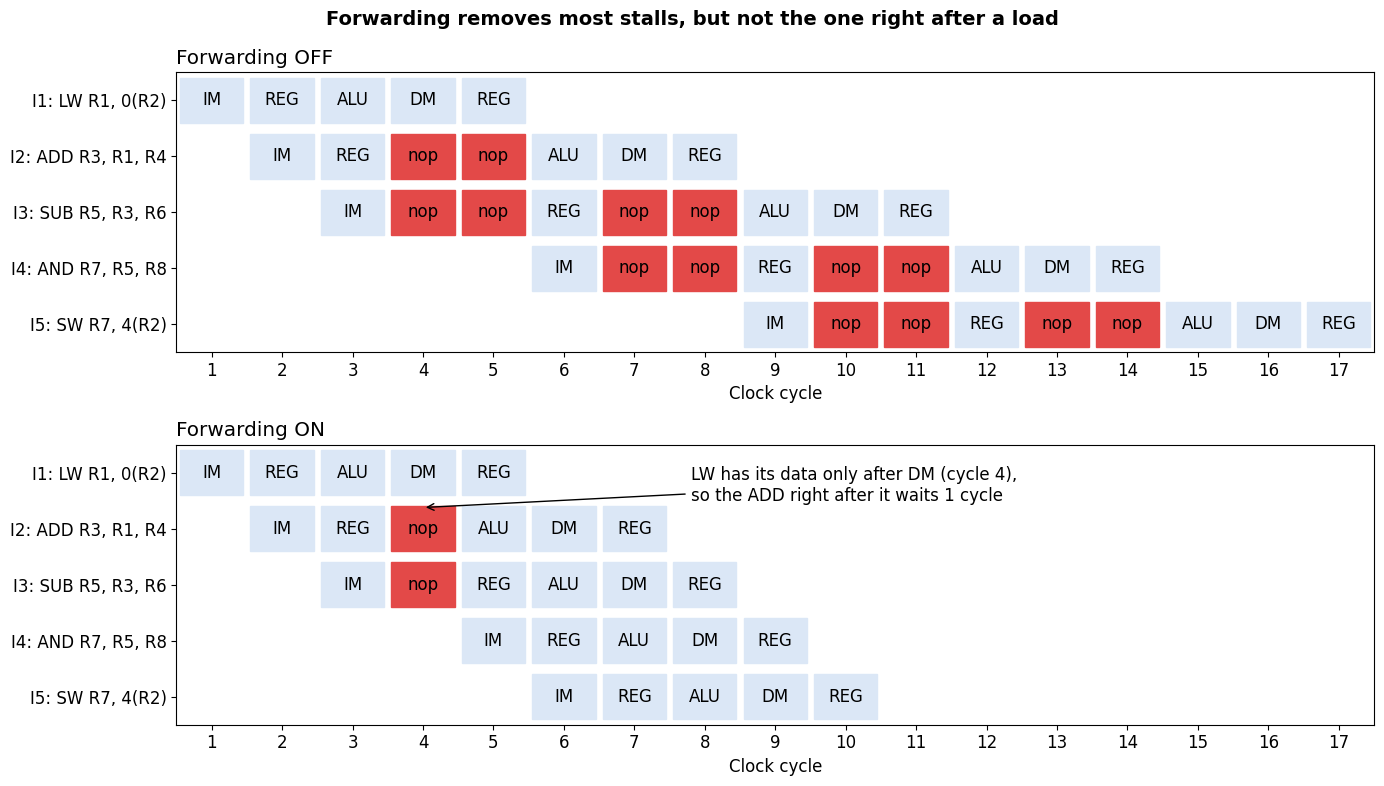

In [4]:
# Graph 1: pipeline diagram
STAGE_NAME = {"IF": "IM", "ID": "REG", "EX": "ALU", "MEM": "DM", "WB": "REG"}

labels = ["I1: LW R1, 0(R2)", "I2: ADD R3, R1, R4", "I3: SUB R5, R3, R6",
          "I4: AND R7, R5, R8", "I5: SW R7, 4(R2)"]

last_cycle = run_off["cycleCount"] - 1


def draw_pipeline(ax, run, title):
    for cycle in range(1, last_cycle + 1):
        for stage in ["IF", "ID", "EX", "MEM", "WB"]:
            i = run["stage"][stage][cycle]
            if i is None:
                continue
            color = STAGE_COLOR
            text = STAGE_NAME[stage]
            if run["stage"][stage][cycle - 1] == i:
                color = STALL_COLOR
                text = "nop"
            ax.add_patch(plt.Rectangle((cycle - 0.45, i - 0.4), 0.9, 0.8, color=color))
            ax.text(cycle, i, text, ha="center", va="center")

    ax.set_yticks(range(5))
    ax.set_yticklabels(labels)
    ax.set_ylim(4.5, -0.5)
    ax.set_xticks(range(1, last_cycle + 1))
    ax.set_xlim(0.5, last_cycle + 0.5)
    ax.set_xlabel("Clock cycle")
    ax.set_title(title, loc="left")


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))
draw_pipeline(ax1, run_off, "Forwarding OFF")
draw_pipeline(ax2, run_on, "Forwarding ON")
ax2.annotate("LW has its data only after DM (cycle 4),\nso the ADD right after it waits 1 cycle",
             xy=(4, 0.62), xytext=(7.8, 0.5), arrowprops={"arrowstyle": "->"})
fig.suptitle("Forwarding removes most stalls, but not the one right after a load",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("images/1_pipeline_data_hazards.png", dpi=150)
plt.show()

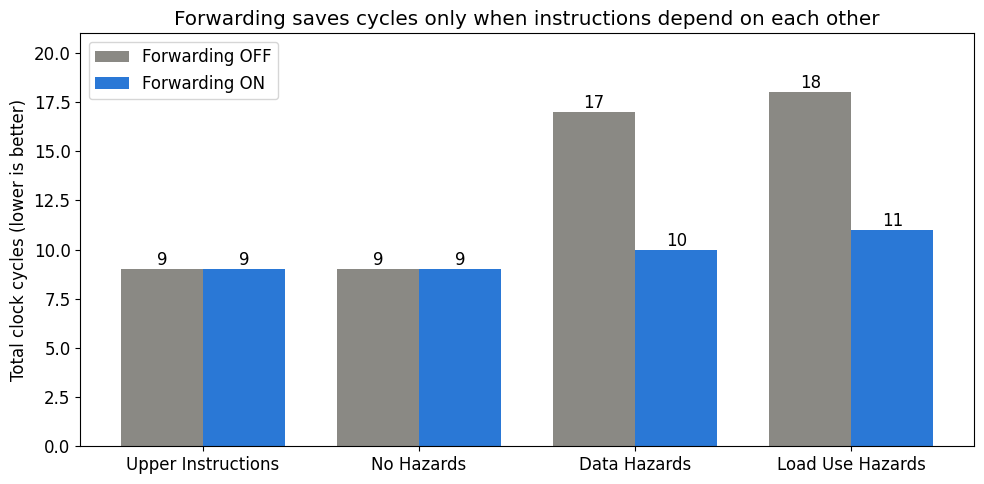

In [5]:
# Graph 2: total clock cycles
x = np.arange(len(names))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
bars_off = ax.bar(x - w / 2, cycles_off, w, color=OFF_COLOR, label="Forwarding OFF")
bars_on = ax.bar(x + w / 2, cycles_on, w, color=ON_COLOR, label="Forwarding ON")
ax.bar_label(bars_off)
ax.bar_label(bars_on)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Total clock cycles (lower is better)")
ax.set_ylim(0, cycles_off.max() + 3)
ax.set_title("Forwarding saves cycles only when instructions depend on each other")
ax.legend()
fig.tight_layout()
fig.savefig("images/2_total_cycles.png", dpi=150)
plt.show()

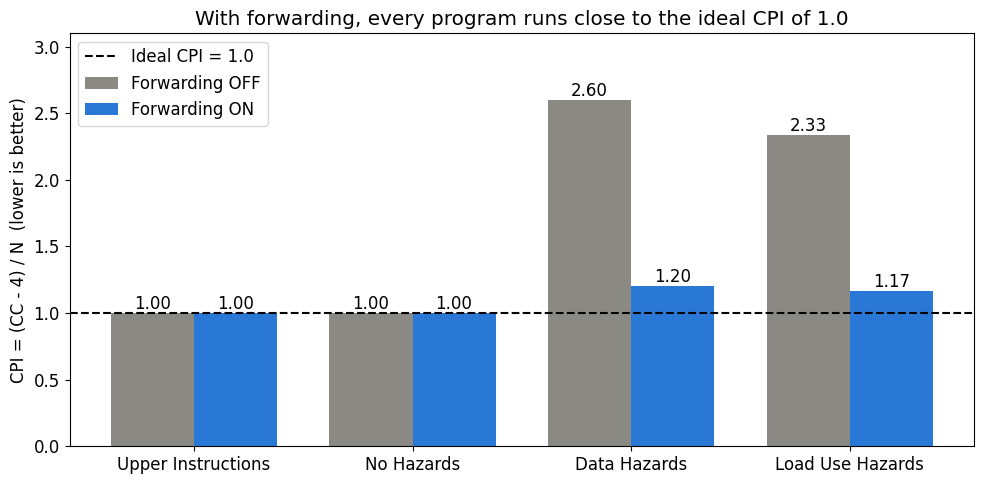

In [6]:
# Graph 3: CPI vs ideal
fig, ax = plt.subplots(figsize=(10, 5))
bars_off = ax.bar(x - w / 2, cpi_off, w, color=OFF_COLOR, label="Forwarding OFF")
bars_on = ax.bar(x + w / 2, cpi_on, w, color=ON_COLOR, label="Forwarding ON")
ax.bar_label(bars_off, fmt="%.2f")
ax.bar_label(bars_on, fmt="%.2f")
ax.axhline(1.0, color="black", linestyle="dashed", label="Ideal CPI = 1.0")

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("CPI = (CC - 4) / N  (lower is better)")
ax.set_ylim(0, cpi_off.max() + 0.5)
ax.set_title("With forwarding, every program runs close to the ideal CPI of 1.0")
ax.legend()
fig.tight_layout()
fig.savefig("images/3_cpi_vs_ideal.png", dpi=150)
plt.show()